In [138]:
from dotenv import load_dotenv
load_dotenv()

True

In [139]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_community.vectorstores import InMemoryVectorStore


In [140]:
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph,START,END

In [141]:
loader = PyPDFLoader("../data/rag-pdf3.pdf")

pagess = loader.load()

In [142]:
splitter=RecursiveCharacterTextSplitter(chunk_size=200,chunk_overlap=50)
chunks=splitter.split_documents(pages)

In [143]:
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

In [144]:
vector_store = Chroma.from_documents(
    documents=chunks,
    embedding=embeddings
)

In [145]:
test_docs = vector_store.similarity_search(
    "What is the patient's full name?",
    k=4
)

for doc in test_docs:
    print("PAGE:", doc.metadata.get("page"))
    print(doc.page_content)
    print("-" * 50)

PAGE: 0
Attending MD: Dr. E. Vance,MD, FACC Referring MD: Dr. R. Sterling,MD Service: Cardiology
1. PRIMARY & SECONDARY DIAGNOSES
--------------------------------------------------
PAGE: 0
Attending MD: Dr. E. Vance,MD, FACC Referring MD: Dr. R. Sterling,MD Service: Cardiology
1. PRIMARY & SECONDARY DIAGNOSES
--------------------------------------------------
PAGE: 0
Attending MD: Dr. E. Vance,MD, FACC Referring MD: Dr. R. Sterling,MD Service: Cardiology
1. PRIMARY & SECONDARY DIAGNOSES
--------------------------------------------------
PAGE: 3
10. PATIENT EDUCATION & ACKNOWLEDGMENT SUMMARY
The patient was counseled extensively prior to discharge regarding diagnosis, drug action, side effect proﬁles
--------------------------------------------------


In [146]:
llm = ChatGroq(model="openai/gpt-oss-120b",streaming="True")

In [147]:
class RagState(BaseModel):
    question:str=Field(description="User Questions")
    documents:list=[]
    context:str=Field(description="Context Data for user questions",default="")
    answer:str=Field(description="Final Answer",default="")


In [148]:
def retrieve_node(state: RagState) -> RagState:

    search_query = f"Patient Name. {state.question}"

    docs = vector_store.similarity_search(
        query=search_query,
        k=10
    )

    # Remove duplicate chunks
    unique_docs = []
    seen = set()

    for doc in docs:
        content = doc.page_content.strip()

        if content not in seen:
            seen.add(content)
            unique_docs.append(doc)

    state.documents = unique_docs[:4]

    return state

In [149]:
def create_context_node(state:RagState) -> RagState:
    context=""
    for docs in state.documents:
        context+=docs.page_content + "\n\n"
    
    state.context=context
    return state

In [150]:
def generate_node(state:RagState) -> RagState:
    prompt = f"""
    You are a helpful assistant.
    Answer the user's question based only on the provided context.

    If the answer is not available in the context, say "I don't know".

    Context:
    {state.context}

    Question:
    {state.question}

    Answer:
    """
    
    response=llm.invoke(prompt)

    state.answer=response.content
    return state



In [151]:
graph=StateGraph(RagState)

graph.add_node("retrieve_node",retrieve_node)
graph.add_node("create_context_node",create_context_node)
graph.add_node("generate_node",generate_node)

graph.add_edge(START,"retrieve_node")
graph.add_edge("retrieve_node","create_context_node")
graph.add_edge("create_context_node","generate_node")
graph.add_edge("generate_node",END)

graph=graph.compile()



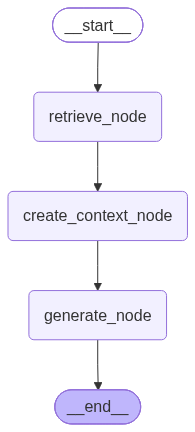

In [152]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [155]:
response=graph.invoke({"question":"What is age of the patient?"})

print(response["answer"])

60 years old.
